In [3]:
import matplotlib.pyplot as plt
import numpy as np

In [16]:
#Parametri koje koristimo u zadatku
alpha = 2.35
M_min = 0.08 
M_max = 200
N = 10000 
#generisemo N slicajnih brojeve
u = np.random.uniform(0, 1, N)
#inverzna finkcija za mase
mase = (M_min**(1-alpha) + u*(M_max**(1-alpha) - M_min**(1-alpha)))**(1/(1-alpha))


Na času smo uveli Salpeov zakon iz čeka smo dalje izveli inveznu funkciju.

In [47]:
#relacija luminoznosti i mase 
L = mase**3.5
#apsolutna magnituda
M_abs = 4.74 - 2.5*np.log10(L)

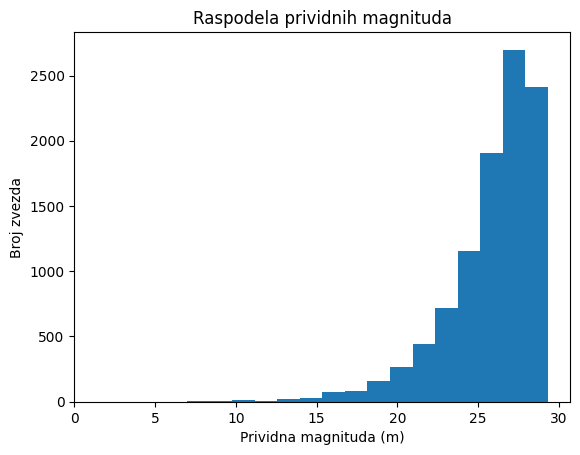

In [91]:
u_r = np.random.uniform(0, 1, N)
#maksimalna udaljenost
d = 10000 #pc
#generisanje udaljenosti zvezda
r = d * u_r**(1/3)
#zapremina sfere
V = (4/3)*d**3 * np.pi 
#prividna magnituda
m = M_abs + 5*np.log10(r) - 5
#plot histograma
plt.hist(m, bins=20)
plt.xlabel("Prividna magnituda (m)")
plt.ylabel("Broj zvezda")
plt.title("Raspodela prividnih magnituda")
plt.show()

Primecujemo da broj zvezda sa vecim prividnim magnitudama raste ,sto znaci da preovladjuju zvezde sa manjim prividnim sjajem. Razlog je Salpeterova raspodela.

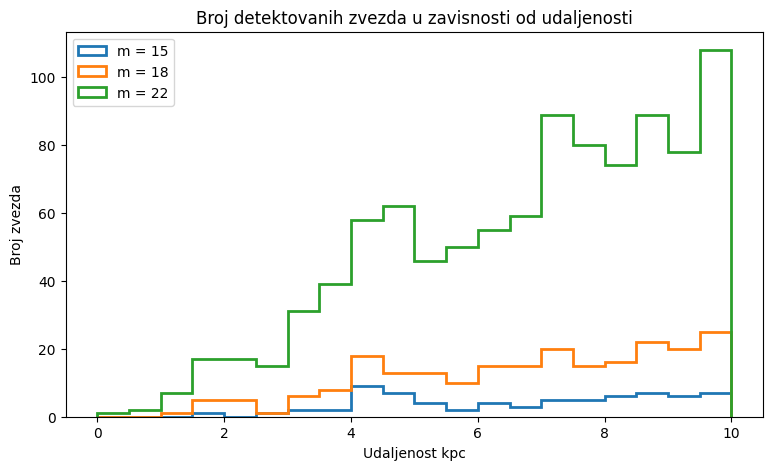

In [97]:
#uslovi zadatka za posmatrane prividne magnitude
m15 = m <= 15
m18 = m <= 18
m22 = m <= 22
#histogrami
plt.figure(figsize=(9, 5))
plt.hist(r[m15]/1000, bins=20, range=(0, 10), histtype="step", linewidth=2, label="m = 15")
plt.hist(r[m18]/1000, bins=20, range=(0, 10), histtype="step", linewidth=2, label="m = 18")
plt.hist(r[m22]/1000, bins=20, range=(0, 10), histtype="step", linewidth=2, label="m = 22") #delimo sa 1000 kako bi presli pc -> kpc
plt.xlabel("Udaljenost kpc")
plt.ylabel("Broj zvezda")
plt.title("Broj detektovanih zvezda u zavisnosti od udaljenosti")
plt.legend()
plt.show()

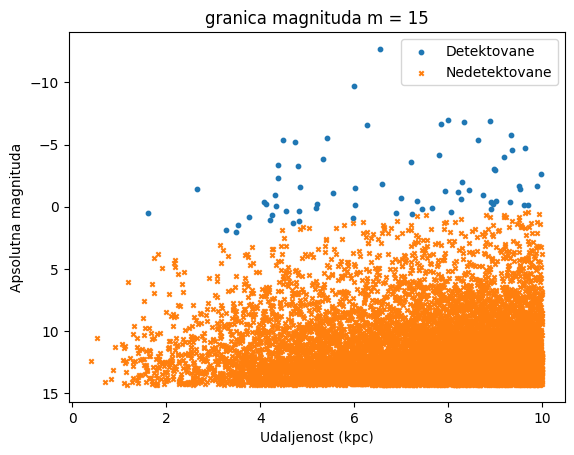

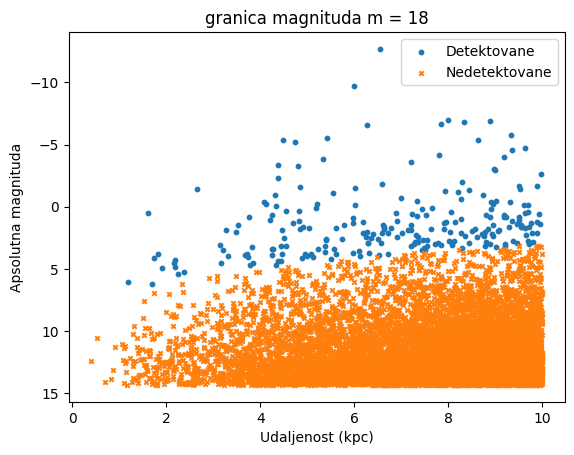

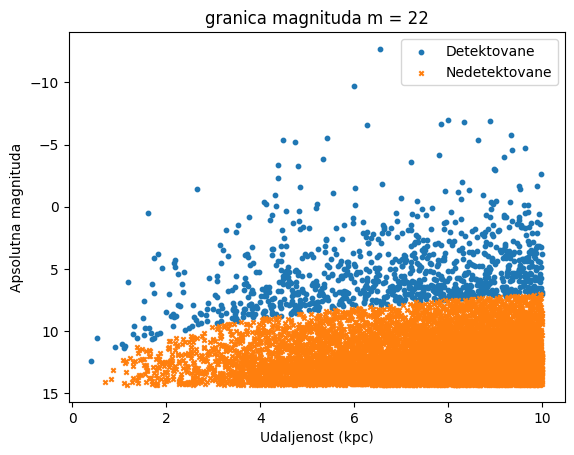

In [125]:
#pravimo petlju kako bi lakse plotovali sva tri uslova
for granica in [15,18,22]:
    #uslov detekcije
    det = m <= granica
    #detektovane zvede 
    plt.scatter(r[det]/1000, M_abs[det], s=10, marker="o", label = "Detektovane")
    #nedetektovane zvezde
    plt.scatter(r[~det]/1000, M_abs[~det], s=10, marker="x", label = "Nedetektovane")

    plt.xlabel("Udaljenost (kpc)")
    plt.ylabel("Apsolutna magnituda")
    plt.title(f"granica magnituda m = {granica}")
    plt.gca().invert_yaxis()
    plt.legend()
    plt.show()
    

Na granicama vidimo da povecanjem granicne prividne magnitude sa 15 na 22 raste broj detektovanih zvezda. Na vecim udaljenostima detektujemo zvezde manje apsolutne magnitude dok slabije zvezde ostaju nedetektovane. Prividni sjaj opada sa rastojanjem pa to posledica prethodnog zapazanja. Zakljucak je da na vecim udaljenostima imamo vecu zastupljenost sjajnijih zvezda u odnosu na stvaran broj.